In [1]:
print("hello world ")

hello world 


Original X shape: (70000, 784)
Original y shape: (70000,)


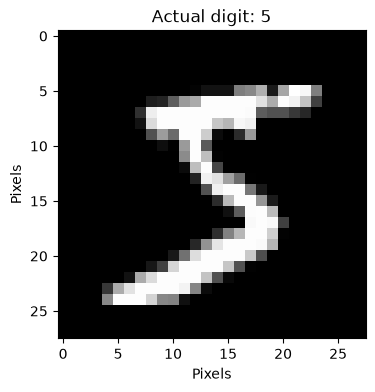

Minimum pixel value: 0.0
Maximum pixel value: 1.0

Training data: (56000, 784)
Testing data: (14000, 784)

Training model...


c:\Users\daksh\anaconda3\envs\adaptive_gnn\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training completed.

Model Accuracy: 0.9202142857142858


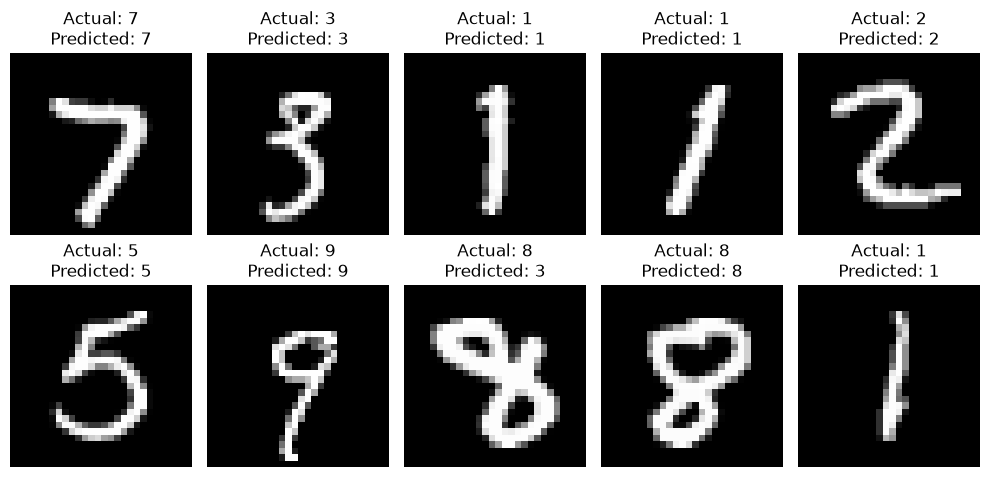

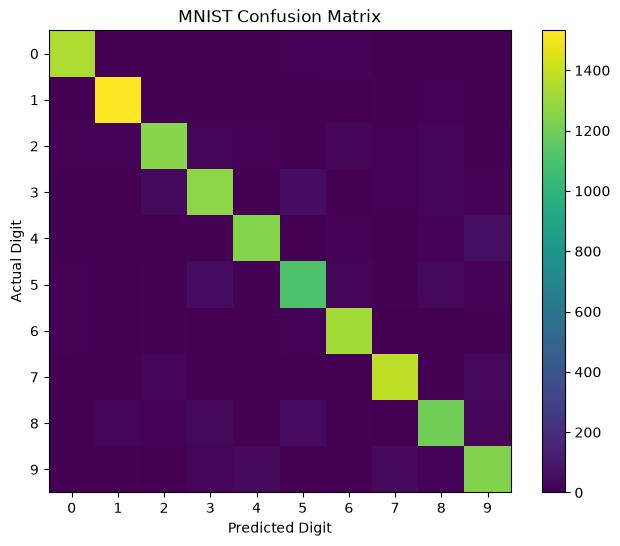


Actual digit: 7
Predicted digit: 7

Prediction probabilities:
Digit 0: 0.0000
Digit 1: 0.0000
Digit 2: 0.0000
Digit 3: 0.0004
Digit 4: 0.0000
Digit 5: 0.0000
Digit 6: 0.0000
Digit 7: 0.9996
Digit 8: 0.0000
Digit 9: 0.0001


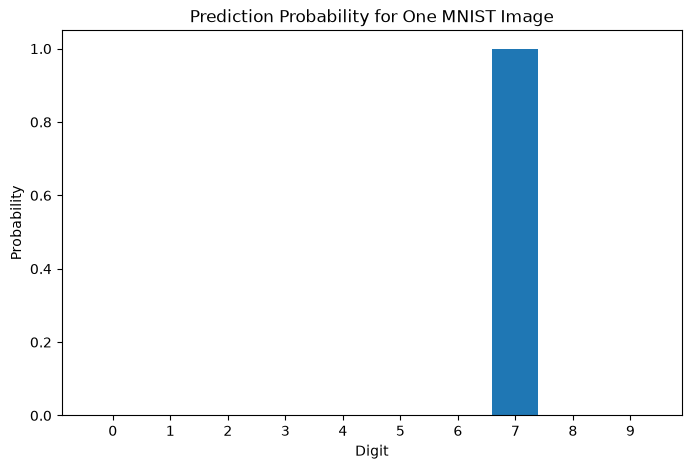


================ MODEL INFORMATION ================
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]
Number of features: 784
Coefficient shape: (10, 784)
Intercept shape: (10,)


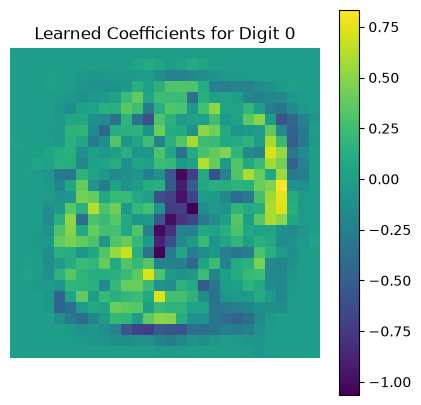

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix


# ============================================================
# 1. LOAD MNIST DATASET
# ============================================================

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False
)

X = mnist.data
y = mnist.target.astype(int)

print("Original X shape:", X.shape)
print("Original y shape:", y.shape)


# ============================================================
# 2. DISPLAY ONE MNIST IMAGE
# ============================================================

plt.figure(figsize=(4, 4))

plt.imshow(
    X[0].reshape(28, 28),
    cmap="gray"
)

plt.title(f"Actual digit: {y[0]}")
plt.xlabel("Pixels")
plt.ylabel("Pixels")
plt.show()


# ============================================================
# 3. NORMALIZE PIXEL VALUES
# ============================================================

X = X / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


# ============================================================
# 4. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 5. CREATE LINEAR MODEL
# ============================================================

model = LogisticRegression(
    max_iter=100,
    solver="lbfgs"
)


# ============================================================
# 6. TRAIN MODEL
# ============================================================

print("\nTraining model...")

model.fit(
    X_train,
    y_train
)

print("Training completed.")


# ============================================================
# 7. MAKE PREDICTIONS
# ============================================================

y_pred = model.predict(X_test)


# ============================================================
# 8. CALCULATE ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nModel Accuracy:", accuracy)


# ============================================================
# 9. DISPLAY ACTUAL VS PREDICTED DIGITS
# ============================================================

plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\n"
        f"Predicted: {y_pred[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.title("MNIST Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()


# ============================================================
# 11. PREDICTION PROBABILITIES FOR ONE IMAGE
# ============================================================

sample = X_test[0].reshape(1, -1)

probabilities = model.predict_proba(sample)[0]

print("\nActual digit:", y_test[0])
print("Predicted digit:", model.predict(sample)[0])

print("\nPrediction probabilities:")

for digit in range(10):

    print(
        f"Digit {digit}: "
        f"{probabilities[digit]:.4f}"
    )


# ============================================================
# 12. PLOT PREDICTION PROBABILITIES
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    range(10),
    probabilities
)

plt.xlabel("Digit")
plt.ylabel("Probability")
plt.title("Prediction Probability for One MNIST Image")

plt.xticks(range(10))

plt.show()


# ============================================================
# 13. DISPLAY MODEL INFORMATION
# ============================================================

print("\n================ MODEL INFORMATION ================")

print("Number of classes:", len(model.classes_))
print("Classes:", model.classes_)

print(
    "Number of features:",
    model.n_features_in_
)

print(
    "Coefficient shape:",
    model.coef_.shape
)

print(
    "Intercept shape:",
    model.intercept_.shape
)


# ============================================================
# 14. VISUALIZE ONE MODEL COEFFICIENT IMAGE
# ============================================================

plt.figure(figsize=(5, 5))

plt.imshow(
    model.coef_[0].reshape(28, 28)
)

plt.title(
    "Learned Coefficients for Digit 0"
)

plt.colorbar()

plt.axis("off")

plt.show()